# KdV equation: data generation

The benchmark of Yildiz, Goyal and Benner (2025), used for energy-preserving operator
inference by Gkimisis, Pontes Duff, Goyal and Benner (2026). Only what differs from
problem 1 is explained; the observation protocol and the compression are identical.

In [1]:
import numpy as np
import scipy.sparse as sparse
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt
import time

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# --------------------- Experiment configuration  -------------------
P = 2.0                    # domain length, as in the reference
GAMMA = 0.022              # dispersion parameter; it enters the PDE as gamma^2
ETA = 1.0                  # coefficient of w dw/dx (see section 1.1)
NX = 500                   # grid points: dx = 0.004, as in the reference

# Input parameters (a, b) = (amplitude, width) of the initial pulse: the four corners
# and the centre of [0.3, 0.5] x [0.8, 1.2].  The centre (0.4, 1.0) is the
# reference's own initial condition.
TRAIN_PARAMS = [(0.30, 0.8), (0.50, 0.8), (0.30, 1.2), (0.50, 1.2), (0.40, 1.0)]
TEST_PARAMS = (0.45, 0.9)  # new parameters, used only for testing

T_TRAIN = (0.0, 15.0)      # time window in which data are observed, as in the reference
T_FINAL = 30.0             # end of the prediction window
NUM_TRUTH_TIMES = 501      # output times on [0, T_FINAL] for the reference solution

M = 120                    # number of noisy snapshots per trajectory (section 4.1)
XI = 0.03                  # relative noise level (3 %)
R = 10                     # number of POD modes, as in the reference
M_PRIME = 4 * M            # number of times at which the GP derivatives will be evaluated

DT = 0.005                 # step of the implicit midpoint rule (section 3)
NEWTON_TOL = 1e-13         # relative residual at which the Newton iteration stops
SEED = 20261008            # random seed

print(f"gamma = {GAMMA:g},  gamma^2 = {GAMMA**2:.3e},  eta = {ETA:g}")
print(f"domain [0, {P:g}),  N = {NX},  dx = {P/NX:g},  r = {R},  m = {M},  xi = {XI:.0%}")
print(f"train on [0, {T_TRAIN[1]:g}], predict to {T_FINAL:g}")

gamma = 0.022,  gamma^2 = 4.840e-04,  eta = 1
domain [0, 2),  N = 500,  dx = 0.004,  r = 10,  m = 120,  xi = 3%
train on [0, 15], predict to 30


## 1. The PDE

$$
\frac{\partial w}{\partial t} + \eta\,w\,\frac{\partial w}{\partial x} +
 \gamma^2\,\frac{\partial^3 w}{\partial x^3} = 0,
\qquad x\in[0,P),\ t\in(0,T],
\tag{1}
$$

periodic, with $P=2$ and $\gamma=0.022$. There is no forcing and no viscosity, so (1)
conserves $E=\tfrac12\int_0^Pw^2\,\mathrm dx$ exactly.

### 1.1 Why $\eta$ is kept at 1

The reference writes the coefficient $\eta$ explicitly, but it is not an independent
parameter: if $w$ solves (1), then $v=\eta w$ solves the same equation with $\eta=1$ and
initial condition $\eta w(\cdot,0)$. Changing $\eta$ is therefore the same as rescaling
the amplitude $a$ below, which is already a parameter of the experiment. We keep
$\eta=1$ and let $a$ carry it.

### 1.2 Spatial grid

$x_i = i\,\Delta x$, $i = 0,\dots,N-1$, with $\Delta x = P/N = 0.004$.

In [2]:
x = np.linspace(0.0, P, NX, endpoint=False)   # x = P is NOT a node (it is x_0)
dx = P / NX                                   # grid spacing
n = x.size                                    # number of unknowns

print(f"grid points n = {n},   dx = {dx:g}")
print(f"first nodes: {x[:4]}")
print(f"last  nodes: {x[-3:]}   (next one would be {P:g} = x_0)")

grid points n = 500,   dx = 0.004
first nodes: [0.    0.004 0.008 0.012]
last  nodes: [1.988 1.992 1.996]   (next one would be 2 = x_0)


### 1.3 Initial condition

$$
w(x,0;a,b) = a\,\mathrm{sech}\big(b\,(x-P/2)\big),
$$

a single broad pulse. The reference uses $(a,b)=(0.4,1)$; here the amplitude and the width
are the two parameters, and that point is the centre of the training set.

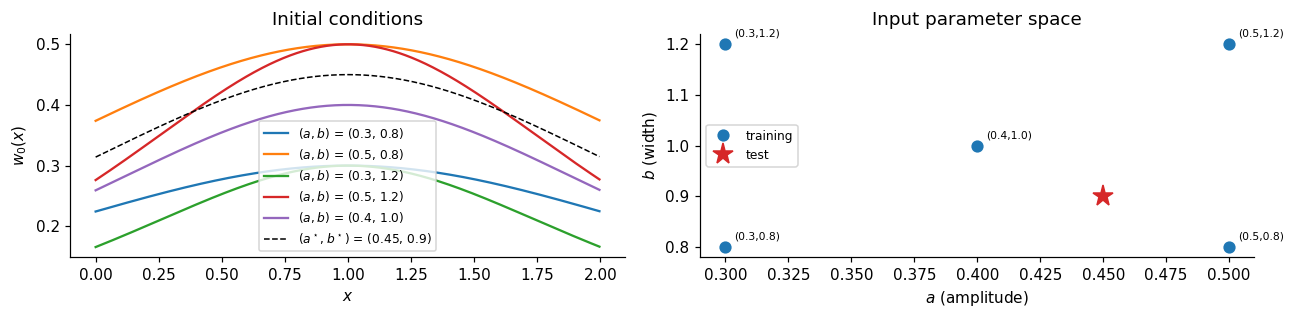

In [3]:
def initial_condition(x, a, b):
    return a / np.cosh(b * (x - P/2))


fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for params in TRAIN_PARAMS:
    axes[0].plot(x, initial_condition(x, *params), label=f"$(a,b)$ = {params}")
axes[0].plot(x, initial_condition(x, *TEST_PARAMS), "k--", lw=1, label=f"$(a^\\star,b^\\star)$ = {TEST_PARAMS}")
axes[0].set(xlabel="$x$", ylabel=r"$w_0(x)$", title="Initial conditions")
axes[0].legend(fontsize=8)

Pm = np.array(TRAIN_PARAMS)
axes[1].plot(Pm[:, 0], Pm[:, 1], "o", ms=7, label="training")
axes[1].plot(*TEST_PARAMS, "*", ms=14, color="C3", label="test")
for a, b in TRAIN_PARAMS:
    axes[1].annotate(f"({a},{b})", (a, b), textcoords="offset points", xytext=(6, 5), fontsize=7)
axes[1].set(xlabel=r"$a$ (amplitude)", ylabel=r"$b$ (width)", title="Input parameter space")
axes[1].legend(fontsize=8, loc="center left")
plt.tight_layout()
plt.show()

## 2. From the PDE to a system of ODEs

At each node $i=0,\dots,N-1$, with all indices modulo $N$:

$$
\dot w_i = -\frac{\gamma^2}{2\Delta x^3}\big(w_{i+2}-2w_{i+1}+2w_{i-1}-w_{i-2}\big)
 \;-\;\frac{\eta}{3}\frac{w_{i+1}^2-w_{i-1}^2}{2\Delta x}
 \;-\;\frac{\eta\,w_i}{3}\frac{w_{i+1}-w_{i-1}}{2\Delta x},
$$

that is

$$
\boxed{\ \frac{\mathrm d\mathbf q}{\mathrm dt}
= \mathbf A_F\mathbf q + \mathbf H_F(\mathbf q\otimes\mathbf q)\ }
$$

with no input, so no $\mathbf B_F\mathbf u$ term. The quadratic part is the
$\lambda=\tfrac23$ member of the family used in problem 1, and the linear part is the
centred third difference. Both stencils are antisymmetric about their centre, so
$\mathbf A_F^\top=-\mathbf A_F$ and $\mathrm{sym}\,\mathbf A_F=\mathbf 0$: the dispersion
neither creates nor destroys energy. That is the one structural difference from problem 1,
where $\mathrm{sym}\,\mathbf A_F\prec\mathbf 0$.

In [4]:
def quad_split(w):
    # H_F(q x q), the lam = 2/3 scheme, scaled by eta.  Expanding lam = 2/3 gives
    #   -(eta/3)(w_{i+1}^2 - w_{i-1}^2)/(2 dx) - (eta/3) w_i (w_{i+1} - w_{i-1})/(2 dx).
    wp, wm = np.roll(w, -1), np.roll(w, 1)
    return ETA * (-(2/3) * (wp**2 - wm**2) / (4 * dx) - (1 - (2/3)) * w * (wp - wm) / (2 * dx))

In [5]:
# Each coefficient of the stencil becomes one diagonal band of A_F, and because the
# grid is a circle each band also wraps to the opposite corner: the band at offset
# k > 0 reappears at offset k - n, and the one at k < 0 at k + n.
coef = GAMMA**2 / (2 * dx**3)

stencil = {+2: -1.0, +1: +2.0, -1: -2.0, -2: +1.0}   # offset i+k -> coefficient

offsets, bands = [], []
for k, c in stencil.items():
    wrap = k - n if k > 0 else k + n
    for offset in (k, wrap):
        offsets.append(offset)
        bands.append(np.full(n - abs(offset), c))

A = coef * sparse.diags(bands, offsets, shape=(n, n), format="csr")

print(f"A_F: {A.shape}, nonzeros = {A.nnz}")

A_F: (500, 500), nonzeros = 2000


In [6]:
def rhs(q):
    # dq/dt = A_F q + H_F(q x q)
    return A @ q + quad_split(q)


def jacobian(q):
    # Jacobian of rhs.  A_F is constant; the quadratic part contributes only the
    # three bands i-1, i, i+1 (and their wraps).
    qp, qm = np.roll(q, -1), np.roll(q, 1)
    d_up = ETA * (-(2/3) * (2*qp) / (4*dx) - (1/3) * q / (2*dx))   # d rhs_i / d q_{i+1}
    d_lo = ETA * (+(2/3) * (2*qm) / (4*dx) + (1/3) * q / (2*dx))   # d rhs_i / d q_{i-1}
    d_di = ETA * (-(1/3) * (qp - qm) / (2*dx))                     # d rhs_i / d q_i
    bands   = [d_di, d_up[:-1], d_lo[1:], d_up[-1:], d_lo[:1]]
    offsets = [0,    1,         -1,       -(n-1),    n-1]
    return A + sparse.diags(bands, offsets, shape=(n, n), format="csr")

In [7]:
# The two structural properties the method relies on, checked numerically.
rng_check = np.random.default_rng(0)
q_test = rng_check.standard_normal(n)

print(f"sym A_F = 0              :  max |A_F + A_F'| = {abs((A + A.T)).max():.3e}")
print(f"A_F annihilates constants:  max |row sum|    = {abs(np.asarray(A.sum(axis=1))).max():.3e}")

ep = q_test @ quad_split(q_test)
scale = np.linalg.norm(q_test)**3 / dx
print(f"q' H_F(q x q) = 0        :  {ep:+.3e}  ({abs(ep)/scale:.1e} relative)")

w_smooth = np.sin(2*np.pi*x/P)
exact = GAMMA**2 * (2*np.pi/P)**3 * np.cos(2*np.pi*x/P)
print(f"A_F vs -gamma^2 w_xxx on sin(2 pi x / P):  relative error "
      f"{np.linalg.norm(A @ w_smooth - exact)/np.linalg.norm(exact):.3e}  (O(dx^2))")

sym A_F = 0              :  max |A_F + A_F'| = 0.000e+00
A_F annihilates constants:  max |row sum|    = 0.000e+00
q' H_F(q x q) = 0        :  +1.364e-12  (4.7e-19 relative)
A_F vs -gamma^2 w_xxx on sin(2 pi x / P):  relative error 3.948e-05  (O(dx^2))


## 3. Time integration

### 3.1 The implicit midpoint rule

$$
\mathbf q_{k+1} = \mathbf q_k + \Delta t\,
\mathbf f\!\left(\tfrac12(\mathbf q_k+\mathbf q_{k+1})\right),
$$

solved for $\mathbf q_{k+1}$ by Newton iteration with the sparse Jacobian above.

Two reasons, both specific to this problem. First, the midpoint rule conserves *every*
quadratic first integral exactly, at any step size. Our semidiscrete system has
$\mathrm{sym}\,\mathbf A_F=\mathbf 0$ and $\mathbf q^\top\mathbf H_F(\mathbf q\otimes\mathbf q)=0$,
so $E=\tfrac{\Delta x}{2}\mathbf q^\top\mathbf q$ is one of them, and it is conserved to
round-off. Problem 2 exists to test the method where nothing dissipates energy; a reference
solution that quietly loses some would defeat the point. Yildiz et al. use a
structure-preserving integrator for the same reason.

Second, $\mathbf A_F$ is skew-symmetric with large purely imaginary eigenvalues,
$|\lambda|_{\max}\approx 2.6\,\gamma^2/\Delta x^3\approx 2\times10^4$. An explicit scheme
would be limited to $\Delta t\lesssim 10^{-4}$, and an error-controlled implicit solver such
as `Radau` spends its effort resolving fast dispersive oscillation that carries almost no
energy. At $\Delta t = 0.005$ the midpoint rule reaches $t=1$ in under half a second, where
`Radau` at `rtol` $=10^{-9}$ takes about a minute.

One caveat: $\mathrm{sech}(x-P/2)$ is not smooth when extended periodically -- its first
derivative jumps at $x=0$ -- and the dispersion radiates that corner into grid-scale waves.
They carry little energy but set an accuracy floor of about $10^{-3}$ relative, which is why
the projection errors in section 5.3 stop improving near $10^{-2}$.

In [8]:
def solve_fom(a, b, t_out):
    """Integrate dq/dt = f(q), q(0) = w0(a,b), returning Q of shape (n, len(t_out)).

    Fixed step DT; t_out must be a non-decreasing list of multiples of DT.
    """
    q = initial_condition(x, a, b)
    identity = sparse.identity(n, format="csr")
    targets = np.asarray(t_out, dtype=float)

    columns, next_out = [], 0
    while next_out < targets.size and targets[next_out] <= 1e-12:
        columns.append(q.copy()); next_out += 1

    for k in range(1, int(round(targets[-1] / DT)) + 1):
        q_new = q.copy()                        # Newton on  g(q_new) = 0
        for _ in range(50):
            mid = 0.5 * (q + q_new)
            g = q_new - q - DT * rhs(mid)
            if np.linalg.norm(g) <= NEWTON_TOL * max(1.0, np.linalg.norm(q_new)):
                break
            g_jac = identity - 0.5 * DT * jacobian(mid)
            q_new = q_new - spla.spsolve(g_jac.tocsc(), g)
        else:
            raise RuntimeError(f"Newton did not converge at step {k}")
        q = q_new
        t = k * DT
        while next_out < targets.size and targets[next_out] <= t + 1e-12:
            columns.append(q.copy()); next_out += 1

    return np.array(columns).T


def on_grid(t):
    """Round times to the integration grid, since the step is fixed."""
    return np.round(np.asarray(t) / DT) * DT

### 3.2 The reference solution

Solved on $501$ times in $[0,30]$ for each training $(a,b)$ and for the test value. It is
not given to the learning algorithm; it is used only to plot and to measure errors,
including on the prediction window $t\in(15,30]$.

In [9]:
t_truth = on_grid(np.linspace(0.0, T_FINAL, NUM_TRUTH_TIMES))

truth = {}         # dict: (a, b) -> array (n, len(t_truth))
energy_drift = {}  # dict: (a, b) -> |E(t)/E(0) - 1| at every output time
t0 = time.time()
for params in TRAIN_PARAMS + [TEST_PARAMS]:
    truth[params] = solve_fom(*params, t_truth)
    Q = truth[params]
    E = 0.5 * (Q**2).sum(axis=0) * dx          # discrete energy at each output time
    energy_drift[params] = np.abs(E / E[0] - 1)
    print(f"(a,b) = {str(params):12s} w in [{Q.min():+.4f}, {Q.max():+.4f}]   "
          f"max |dE/E| = {energy_drift[params].max():.2e}")

worst_drift = max(d.max() for d in energy_drift.values())

# The midpoint rule conserves E exactly in exact arithmetic, so what is left is the
# accumulation of rounding over the K steps taken, which random-walks like sqrt(K)*eps.
# The exact figure depends on the machine's BLAS and is not reproducible digit for
# digit; its order of magnitude is.
n_steps = int(round(T_FINAL / DT))
roundoff_scale = np.sqrt(n_steps) * np.finfo(float).eps

print(f"\nworst over all trajectories and all times: |dE/E| = {worst_drift:.2e}")
print(f"round-off scale sqrt(K)*eps, K = {n_steps} steps:  {roundoff_scale:.2e}")
print("-> energy conserved to round-off" if worst_drift < roundoff_scale
      else "-> WARNING: drift exceeds the round-off scale")
print(f"\ntotal wall time: {time.time() - t0:.1f} s")

(a,b) = (0.3, 0.8)   w in [+0.2243, +0.3390]   max |dE/E| = 6.88e-15
(a,b) = (0.5, 0.8)   w in [+0.3738, +0.5712]   max |dE/E| = 4.88e-15
(a,b) = (0.3, 1.2)   w in [+0.1657, +0.3740]   max |dE/E| = 1.11e-14
(a,b) = (0.5, 1.2)   w in [+0.2761, +0.6454]   max |dE/E| = 2.89e-15
(a,b) = (0.4, 1.0)   w in [+0.2592, +0.4798]   max |dE/E| = 1.12e-14
(a,b) = (0.45, 0.9)  w in [+0.3140, +0.5274]   max |dE/E| = 4.44e-15

worst over all trajectories and all times: |dE/E| = 1.12e-14
round-off scale sqrt(K)*eps, K = 6000 steps:  1.72e-14
-> energy conserved to round-off

total wall time: 23.1 s


### 3.3 Energy of the reference solution

The semidiscrete system has $\mathrm{sym}\,\mathbf A_F=\mathbf 0$ and
$\mathbf q^\top\mathbf H_F(\mathbf q\otimes\mathbf q)=0$, so
$E=\tfrac{\Delta x}{2}\mathbf q^\top\mathbf q$ is a quadratic first integral and the
midpoint rule conserves it exactly. This is the quantity problem 2 is built around, so
it is worth checking rather than assuming. What is left is floating-point round-off,
which accumulates as a random walk and so creeps slowly upward in magnitude, but
stays at the level of $\sqrt{K}\,\epsilon_{\mathrm{mach}}$ for the $K$ steps taken ---
some twelve orders of magnitude below the energy drift any inferred model will show.
Because it is round-off, the exact figure depends on the machine's arithmetic and will
differ in its last digits from one run to another on different hardware; the check below
is against that scale, not against a stored number.

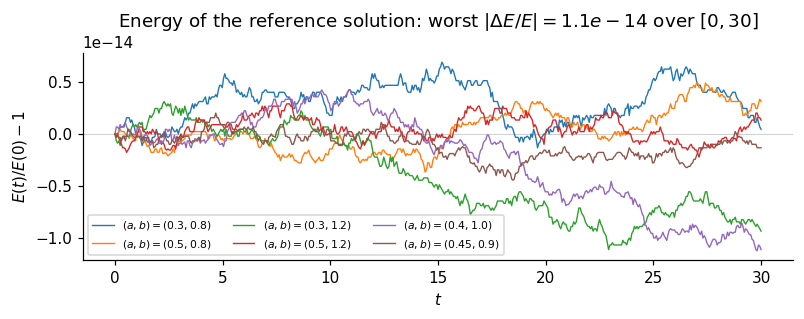

In [10]:
# E = (dx/2) q'q is a quadratic first integral of the semidiscrete system, because
# sym A_F = 0 and q' H_F(q x q) = 0 (verified above).  The implicit midpoint rule
# conserves every quadratic first integral exactly, so the only departure from a
# constant here is floating-point round-off: a random walk at the 1e-15 level,
# not a systematic loss or gain of energy.
fig, ax = plt.subplots(figsize=(7.5, 3))
for params in TRAIN_PARAMS + [TEST_PARAMS]:
    Q = truth[params]
    E = 0.5 * (Q**2).sum(axis=0) * dx
    ax.plot(t_truth, E / E[0] - 1, lw=0.9, label=f"$(a,b)={params}$")
ax.axhline(0.0, color="0.8", lw=0.6, zorder=-1)
ax.set(xlabel="$t$", ylabel=r"$E(t)/E(0)-1$",
       title=f"Energy of the reference solution: worst $|\\Delta E/E| = "
             f"{worst_drift:.1e}$ over $[0,{T_FINAL:g}]$")
ax.legend(fontsize=7, ncol=3)
plt.tight_layout()
plt.show()

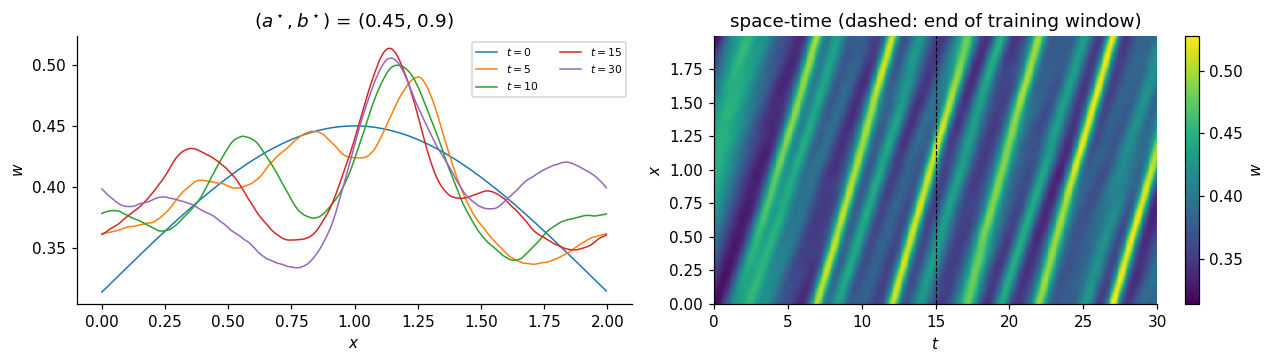

In [11]:
# The reference solution for the test parameters.
Q = truth[TEST_PARAMS]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for t_show in (0.0, 5.0, 10.0, 15.0, 30.0):
    j = np.argmin(abs(t_truth - t_show))
    axes[0].plot(x, Q[:, j], lw=1.0, label=f"$t = {t_truth[j]:.0f}$")
axes[0].set(xlabel="$x$", ylabel="$w$", title=rf"$(a^\star,b^\star)$ = {TEST_PARAMS}")
axes[0].legend(fontsize=7, ncol=2)

# w stays positive here, so a sequential scale over its own range, not a
# diverging one centred at zero.
im = axes[1].pcolormesh(t_truth, x, Q, shading="auto", cmap="viridis",
                        vmin=Q.min(), vmax=Q.max())
axes[1].axvline(T_TRAIN[1], color="k", ls="--", lw=0.8)
axes[1].set(xlabel="$t$", ylabel="$x$", title="space-time (dashed: end of training window)")
fig.colorbar(im, ax=axes[1], label="$w$")
plt.tight_layout()
plt.show()

## 4. Sparse, noisy observations

### 4.1 Random observation times

For each trajectory independently, $m=120$ times: the two endpoints of $[0,15]$ and
$m-2$ sorted uniform draws from it, rounded to the integration grid.

The count is set by the motion, not by the length of the window. The reduced
coordinates retained at $r=10$ oscillate with periods between $1.2$ and $5$ (measured in
section 1.1 of the method notebook), so a spacing of $15/119\approx0.13$ gives nine
samples per oscillation on the fastest coordinate and forty on the slowest: enough to
resolve the motion, and no more. These $120$ snapshots are $2\,\%$ of the $6000$ steps
the reference solution is advanced through.

### 4.2 Relative noise

$$
\mathbf q_j = \mathbf q(t_j) + \boldsymbol\varepsilon_j,\qquad
\boldsymbol\varepsilon_j\sim\mathcal N\big(\mathbf 0,\ \mathrm{diag}(\xi\,\mathbf q(t_j))^2\big),
\qquad \xi = 0.03,
$$

entrywise $(\mathbf q_j)_i = w_i(t_j) + \xi|w_i(t_j)|z_{ij}$, with no noise at $t_0=0$
since the initial condition is given. The same noise model and the same level as
problem 1, with no input to record.

In [12]:
def sample_times(m, t_span):
    # m sorted uniform times in t_span, endpoints forced, rounded to the DT grid.
    t = np.sort(np.random.uniform(t_span[0], t_span[1], size=m))
    t[0], t[-1] = t_span
    return on_grid(t)

def add_noise(Q, xi):
    # Relative Gaussian noise on all nodes, at times t_j with j >= 1.
    Qn = Q.copy()
    body = Q[:, 1:]                                  # skip the first column (t_0)
    Qn[:, 1:] = body + xi * np.abs(body) * np.random.standard_normal(body.shape)
    return Qn

np.random.seed(SEED)

obs_times = []        # list of L arrays, shape (m,)
snapshots_clean = []  # list of L arrays, shape (n, m): exact solution at those times
snapshots = []        # list of L arrays, shape (n, m): noisy  <- the ONLY training data
for params in TRAIN_PARAMS:
    t_obs = sample_times(M, T_TRAIN)             # random draws 1: times
    Q_obs = solve_fom(*params, t_obs)            # exact solution at those times
    Q_noisy = add_noise(Q_obs, XI)               # random draws 2: noise
    obs_times.append(t_obs)
    snapshots_clean.append(Q_obs)
    snapshots.append(Q_noisy)

print("snapshots per trajectory:", snapshots[0].shape,
      "  total:", sum(S.shape[1] for S in snapshots))

snapshots per trajectory: (500, 120)   total: 600


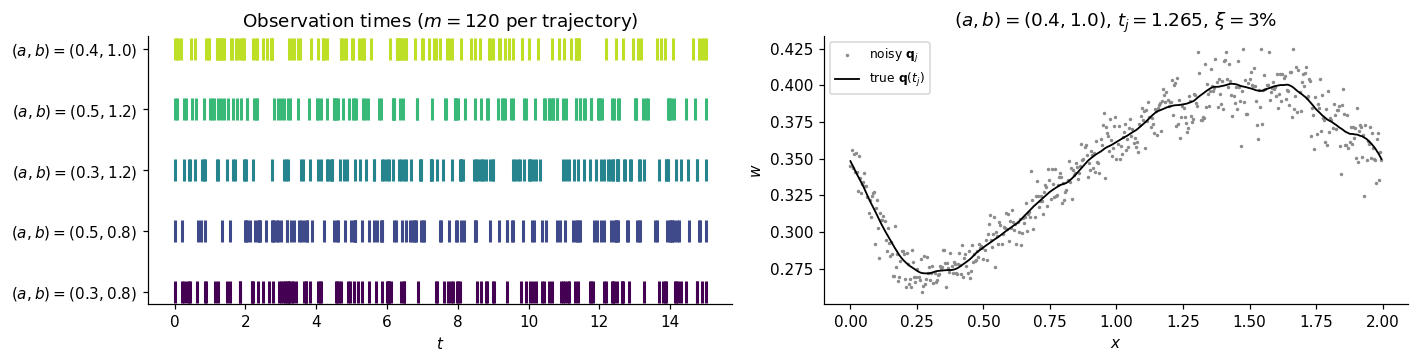

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))

colors = plt.cm.viridis(np.linspace(0, 0.9, len(TRAIN_PARAMS)))

# Left: the irregular observation times of each trajectory.
for l, (t_obs, params) in enumerate(zip(obs_times, TRAIN_PARAMS)):
    axes[0].plot(t_obs, np.full(M, l), "|", ms=14, mew=2, color=colors[l])
axes[0].set_yticks(range(len(TRAIN_PARAMS)))
axes[0].set_yticklabels([f"$(a,b)=({a},{b})$" for a, b in TRAIN_PARAMS])
axes[0].set(xlabel="$t$", title=f"Observation times ($m={M}$ per trajectory)")

# Right: one noisy snapshot vs. the truth.
l, j = 4, 12
axes[1].plot(x, snapshots[l][:, j], ".", ms=2.5, color="0.55", label=r"noisy $\mathbf{q}_j$")
axes[1].plot(x, snapshots_clean[l][:, j], "k", lw=1.2, label=r"true $\mathbf{q}(t_j)$")
axes[1].set(xlabel="$x$", ylabel="$w$",
            title=f"$(a,b)={TRAIN_PARAMS[l]}$, $t_j={obs_times[l][j]:.3f}$, "
                  f"$\\xi={XI:.0%}$".replace("%", r"\%"))
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. Compression

### 5.1 POD

As in problem 1, the basis is centred on the snapshot mean $\bar{\mathbf q}$. From the thin
SVD of all $L\times m=600$ noisy snapshots minus $\bar{\mathbf q}$, the basis is
$\mathbf V=\mathbf U_{:,1:r}$ with $r=10$ as in the reference, and
$\hat{\mathbf q}_j=\mathbf V^\top(\mathbf q_j-\bar{\mathbf q})$, with intrusive operators

$$
\widehat{\mathbf H}=\mathbf V^\top\mathbf H_F(\mathbf V\otimes\mathbf V),\qquad
\widehat{\mathbf A}=\mathbf V^\top\big(\mathbf A_F+2\mathbf H_F(\bar{\mathbf q}\otimes\mathbf I)\big)\mathbf V,\qquad
\hat{\mathbf c}=\mathbf V^\top\big(\mathbf A_F\bar{\mathbf q}+\mathbf H_F(\bar{\mathbf q}\otimes\bar{\mathbf q})\big).
$$

Note what the shift does to $\alpha$. Because $\mathrm{sym}\,\mathbf A_F=\mathbf 0$, the
uncentred $\mathbf V^\top\mathbf A_F\mathbf V$ is exactly skew and would give $\alpha=0$.
Centring adds $2\mathbf H_F(\bar{\mathbf q}\otimes\mathbf I)$, which is not skew, so $\alpha$
is slightly perturbed off zero. The reference infers with $\hat{\mathbf c}=\mathbf 0$ and so
never sees this; we do, and the number below is how far off zero it lands.

In [14]:
Q_all = np.hstack(snapshots)                        # (n, L*m) = (500, 150), noisy
q_bar = Q_all.mean(axis=1)                          # the mean snapshot profile

U_svd, svals, _ = np.linalg.svd(Q_all - q_bar[:, None], full_matrices=False)
V = U_svd[:, :R]                                    # POD basis, (n, r)

def compress(Q):
    # Full snapshots (n, k) -> reduced coordinates (r, k)
    return V.T @ (Q - q_bar[:, None])

def decompress(Q_hat):
    # Reduced coordinates (r, k) -> full state (n, k)
    return V @ Q_hat + q_bar[:, None]

energy = np.cumsum(svals**2) / np.sum(svals**2)
print(f"snapshot matrix: {Q_all.shape}")
print(f"energy captured by r = {R} modes: {energy[R-1]:.6f}   "
      f"(residual {1 - energy[R-1]:.3e})")

snapshot matrix: (500, 600)
energy captured by r = 10 modes: 0.981935   (residual 1.807e-02)


In [15]:
# The intrusive linear operator about q_bar, and its decay rate.
# 2 H_F(q_bar x v) is recovered from quad_split by polarization.
Qbar = quad_split(q_bar)
Ahat = np.column_stack([V.T @ (A @ V[:, j]
                               + quad_split(q_bar + V[:, j]) - Qbar - quad_split(V[:, j]))
                        for j in range(R)])
chat = V.T @ (A @ q_bar + Qbar)
alpha = -np.linalg.eigvalsh(0.5 * (Ahat + Ahat.T)).max()

A_unshifted = V.T @ (A @ V)
print(f"||sym(V' A_F V)|| = {abs(A_unshifted + A_unshifted.T).max():.3e}   (exactly skew)")
print(f"||q_bar|| = {np.linalg.norm(q_bar):.4f}")
print(f"alpha of the intrusive ROM = {alpha:+.4f}   ||c_hat|| = {np.linalg.norm(chat):.4f}")

||sym(V' A_F V)|| = 3.844e-14   (exactly skew)
||q_bar|| = 7.7359
alpha of the intrusive ROM = -0.0082   ||c_hat|| = 0.5128


/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83696/3249371630.py:4: RuntimeWarning: divide by zero encountered in matmul
  Ahat = np.column_stack([V.T @ (A @ V[:, j]
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83696/3249371630.py:4: RuntimeWarning: overflow encountered in matmul
  Ahat = np.column_stack([V.T @ (A @ V[:, j]
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83696/3249371630.py:4: RuntimeWarning: invalid value encountered in matmul
  Ahat = np.column_stack([V.T @ (A @ V[:, j]
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83696/3249371630.py:7: RuntimeWarning: divide by zero encountered in matmul
  chat = V.T @ (A @ q_bar + Qbar)
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83696/3249371630.py:7: RuntimeWarning: overflow encountered in matmul
  chat = V.T @ (A @ q_bar + Qbar)
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83696/3249371630.py:7: RuntimeWarning: invalid value encountered in matmul
 

In [16]:
# How far the intrusive model is from certifying, and in what way.  This is the
# reference point section 7.4 of the paper quotes; the method notebook reports the
# same quantities for the inferred operators, which are a different object.
import cvxpy as cp

ev_int = np.linalg.eigvalsh(0.5*(Ahat + Ahat.T))
print(f"eigenvalues of sym(A_hat): {(ev_int > 0).sum()} positive, {(ev_int <= 0).sum()} negative")
print(f"   range [{ev_int.min():+.3e}, {ev_int.max():+.3e}],  alpha = {-ev_int.max():+.3e}")

# H_hat as an r x r x r tensor, by polarization on the reduced coordinates.
Hhat = np.zeros((R, R, R))
for j in range(R):
    for k in range(R):
        Hhat[:, j, k] = 0.5 * V.T @ (quad_split(V[:, j] + V[:, k])
                                     - quad_split(V[:, j]) - quad_split(V[:, k]))
print(f"   EP of H_hat: max |H_ijk + H_jik + H_kij| = "
      f"{max(abs(Hhat[i,j,k] + Hhat[j,i,k] + Hhat[k,i,j]) for i in range(R) for j in range(R) for k in range(R)):.2e}")

# min over m of lambda_max(sym(A_hat + L_m)) with L_m = 2 H_hat(m (x) I): a small SDP.
m_var = cp.Variable(R); t_var = cp.Variable()
L_m = sum(2*Hhat[:, k, :]*m_var[k] for k in range(R))
cp.Problem(cp.Minimize(t_var),
           [cp.Constant(0.5*(Ahat + Ahat.T)) + 0.5*(L_m + L_m.T) << t_var*np.eye(R)]
           ).solve(solver=cp.CLARABEL)
L_opt = sum(2*Hhat[:, k, :]*m_var.value[k] for k in range(R))
alpha_m = -np.linalg.eigvalsh(0.5*(Ahat + Ahat.T) + 0.5*(L_opt + L_opt.T)).max()
print(f"\nbest shifted rate over all centres: alpha_m* = {alpha_m:+.3e}  "
      f"at ||m*|| = {np.linalg.norm(m_var.value):.2f}")
print("-> still negative: no centre makes the certificate strict for this model.")

eigenvalues of sym(A_hat): 5 positive, 5 negative
   range [-8.566e-03, +8.174e-03],  alpha = -8.174e-03
   EP of H_hat: max |H_ijk + H_jik + H_kij| = 5.55e-17

best shifted rate over all centres: alpha_m* = -1.554e-03  at ||m*|| = 0.21
-> still negative: no centre makes the certificate strict for this model.


/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83696/1649584175.py:14: RuntimeWarning: divide by zero encountered in matmul
  Hhat[:, j, k] = 0.5 * V.T @ (quad_split(V[:, j] + V[:, k])
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83696/1649584175.py:14: RuntimeWarning: overflow encountered in matmul
  Hhat[:, j, k] = 0.5 * V.T @ (quad_split(V[:, j] + V[:, k])
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83696/1649584175.py:14: RuntimeWarning: invalid value encountered in matmul
  Hhat[:, j, k] = 0.5 * V.T @ (quad_split(V[:, j] + V[:, k])


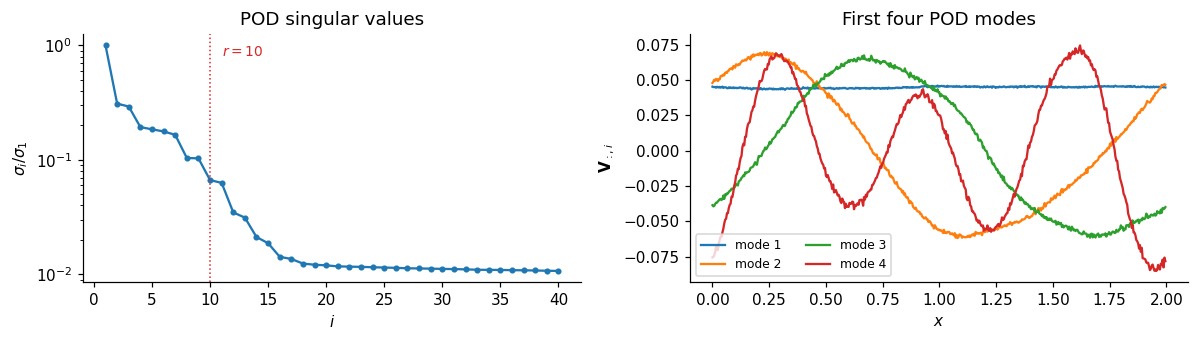

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
n_show_sv = 40
axes[0].semilogy(np.arange(1, n_show_sv + 1), svals[:n_show_sv] / svals[0], "o-", ms=3)
axes[0].axvline(R, color="C3", ls=":", lw=1)
axes[0].text(R + 1.0, 1.0, f"$r={R}$", color="C3", fontsize=9, va="top")
axes[0].set(xlabel="$i$", ylabel=r"$\sigma_i/\sigma_1$", title="POD singular values")

axes[1].plot(x, V[:, :4])
axes[1].set(xlabel="$x$", ylabel=r"$\mathbf{V}_{:,i}$", title="First four POD modes")
axes[1].legend([f"mode {i+1}" for i in range(4)], fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

### 5.2 The reduced coordinate time series

For every trajectory $\ell$ and reduced coordinate $i$ there is one short, irregular, noisy
time series. The lines show the noise-free reference solution compressed with the same
basis. Only the first six coordinates are plotted.

/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83696/1403854733.py:9: RuntimeWarning: divide by zero encountered in matmul
  return V.T @ (Q - q_bar[:, None])
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83696/1403854733.py:9: RuntimeWarning: overflow encountered in matmul
  return V.T @ (Q - q_bar[:, None])
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83696/1403854733.py:9: RuntimeWarning: invalid value encountered in matmul
  return V.T @ (Q - q_bar[:, None])


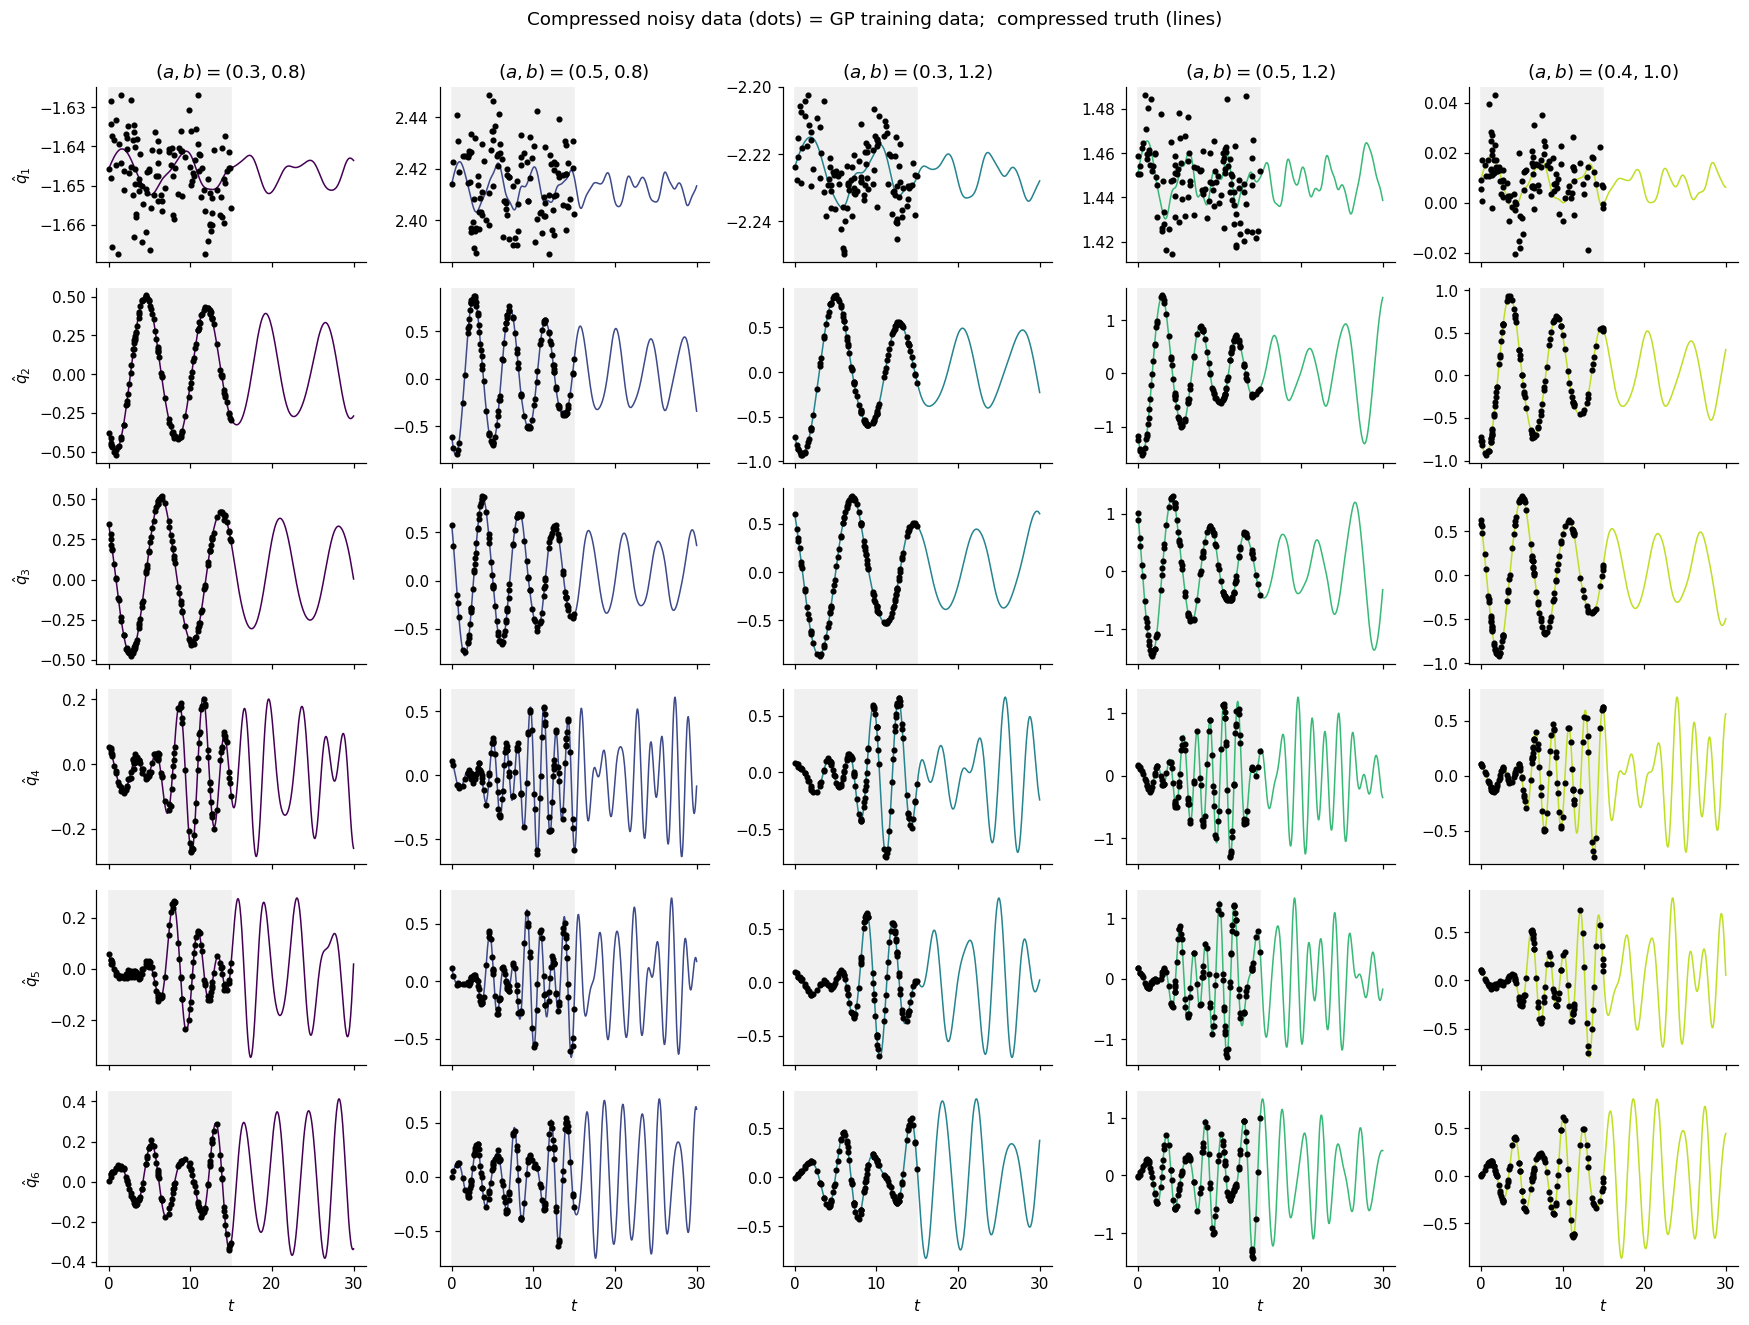

In [18]:
snapshots_compressed = [compress(S) for S in snapshots]           # list of (r, m)
truth_compressed = {p: compress(truth[p]) for p in truth}         # dict of (r, len(t_truth))

n_show = 6
fig, axes = plt.subplots(n_show, len(TRAIN_PARAMS), figsize=(16, 2.0 * n_show), sharex=True)
for l, params in enumerate(TRAIN_PARAMS):
    for i in range(n_show):
        ax = axes[i, l]
        ax.plot(t_truth, truth_compressed[params][i], color=colors[l], lw=1)
        ax.plot(obs_times[l], snapshots_compressed[l][i], "ko", ms=3)
        ax.axvspan(*T_TRAIN, color="0.94", zorder=-1)
        if i == 0:
            ax.set_title(f"$(a,b)={params}$")
        if l == 0:
            ax.set_ylabel(rf"$\hat q_{{{i+1}}}$")
for ax in axes[-1]:
    ax.set_xlabel("$t$")
fig.suptitle("Compressed noisy data (dots) = GP training data;  compressed truth (lines)", y=1.0)
plt.tight_layout()
plt.show()

### 5.3 Projection error

$$
\frac{\|\mathbf Q_{\text{ref}} - \mathbf V\mathbf V^\top\mathbf Q_{\text{ref}}\|_F}
{\|\mathbf Q_{\text{ref}}\|_F}
$$

is a lower bound on the error of any reduced model in this basis. Unlike problem 1 it
barely grows outside the training window, because the solution stays close to one slowly
deforming profile.

         (a,b)   proj. error [0,15]   proj. error [0,30]
    (0.3, 0.8)           6.5048e-03           6.7909e-03
    (0.5, 0.8)           9.0271e-03           9.8929e-03
    (0.3, 1.2)           1.7441e-02           1.8987e-02
    (0.5, 1.2)           3.1795e-02           3.2835e-02
    (0.4, 1.0)           1.4773e-02           1.5296e-02
   (0.45, 0.9)           1.1416e-02           1.2928e-02  (test)


/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83696/1403854733.py:13: RuntimeWarning: divide by zero encountered in matmul
  return V @ Q_hat + q_bar[:, None]
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83696/1403854733.py:13: RuntimeWarning: overflow encountered in matmul
  return V @ Q_hat + q_bar[:, None]
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83696/1403854733.py:13: RuntimeWarning: invalid value encountered in matmul
  return V @ Q_hat + q_bar[:, None]


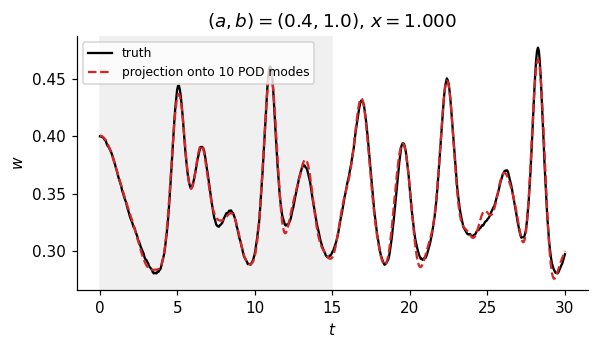

In [19]:
print(f"{'(a,b)':>14s}  {'proj. error [0,15]':>19s}  {'proj. error [0,30]':>19s}")
for params in TRAIN_PARAMS + [TEST_PARAMS]:
    Qt = truth[params]
    Qp = decompress(truth_compressed[params])
    train = t_truth <= T_TRAIN[1]
    e_tr = np.linalg.norm(Qt[:, train] - Qp[:, train]) / np.linalg.norm(Qt[:, train])
    e_all = np.linalg.norm(Qt - Qp) / np.linalg.norm(Qt)
    tag = "  (test)" if params == TEST_PARAMS else ""
    print(f"{str(params):>14s}  {e_tr:19.4e}  {e_all:19.4e}{tag}")

# Visual check at one location for one trajectory.
params, x_loc = TRAIN_PARAMS[4], P/2
i = np.argmin(np.abs(x - x_loc))
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(t_truth, truth[params][i], "k", label="truth")
ax.plot(t_truth, decompress(truth_compressed[params])[i], "C3--",
        label=f"projection onto {R} POD modes")
ax.axvspan(*T_TRAIN, color="0.94", zorder=-1)
ax.set(xlabel="$t$", ylabel="$w$", title=f"$(a,b)={params}$, $x={x[i]:.3f}$")
ax.legend(fontsize=8)
plt.show()

## 6. Save the data

Everything the method notebook needs, plus the reference solution for evaluation only.
There is no input here, so the arrays problem 1 stores for $\mathbf u$ and $\mathbf B_F$
are absent.

In [20]:
# The m' = 120 equally spaced times in [0, 15] at which the GP derivative estimates
# will be evaluated.  These are GP evaluation points, not FOM solves, so they need
# not lie on the DT grid.
t_est = np.linspace(*T_TRAIN, M_PRIME)

np.savez_compressed(
    "data_KdV1D.npz",
    # configuration
    gamma=GAMMA, eta=ETA, xi=XI, r=R, seed=SEED, P=P, dx=dx, dt=DT,
    train_params=np.array(TRAIN_PARAMS), test_params=np.array(TEST_PARAMS),
    x=x, t_truth=t_truth, t_est=t_est, t_train=np.array(T_TRAIN), t_final=T_FINAL,
    # training data (what the method is allowed to see)
    obs_times=np.array(obs_times),                       # (L, m)
    snapshots=np.array(snapshots),                       # (L, n, m)   noisy
    snapshots_clean=np.array(snapshots_clean),           # (L, n, m)   noise free
    snapshots_compressed=np.array(snapshots_compressed), # (L, r, m)
    # POD basis
    V=V, q_bar=q_bar, svals=svals,
    # A_F is not stored because it is fully determined by (gamma, dx): the skew
    # stencil of section 2, four lines to rebuild.  There is no B_F and no input.
    # truth (for evaluation only)
    truth_train=np.array([truth[p] for p in TRAIN_PARAMS]),   # (L, n, 501)
    truth_test=truth[TEST_PARAMS],                            # (n, 501)
    energy_drift=np.array([energy_drift[p] for p in TRAIN_PARAMS + [TEST_PARAMS]]),
)

import os
print(f"saved data_KdV1D.npz  ({os.path.getsize('data_KdV1D.npz')/2**20:.1f} MiB)")

saved data_KdV1D.npz  (14.9 MiB)


In [21]:
# Read it back and check the shapes, so the method notebook starts from known ground.
# dict(...) materializes the arrays, so d stays usable afterwards (d["xi"], d["V"], ...);
# np.load alone returns a lazy archive that closes and leaves the names dead.
d = dict(np.load("data_KdV1D.npz"))
for k in sorted(d):
    print(f"  {k:22s} {str(d[k].shape):16s} {d[k].dtype}")

  P                      ()               float64
  V                      (500, 10)        float64
  dt                     ()               float64
  dx                     ()               float64
  energy_drift           (6, 501)         float64
  eta                    ()               float64
  gamma                  ()               float64
  obs_times              (5, 120)         float64
  q_bar                  (500,)           float64
  r                      ()               int64
  seed                   ()               int64
  snapshots              (5, 500, 120)    float64
  snapshots_clean        (5, 500, 120)    float64
  snapshots_compressed   (5, 10, 120)     float64
  svals                  (500,)           float64
  t_est                  (480,)           float64
  t_final                ()               float64
  t_train                (2,)             float64
  t_truth                (501,)           float64
  test_params            (2,)             float64
  tr